In [1]:
import numpy as np
import pandas as pd

np.random.seed(42)

# Generate 200 students
n = 200

cgpa = np.random.uniform(5.0, 9.8, n)

# Placement package in LPA
package = 1.5 * cgpa - 5 + np.random.normal(0, 1.2, n)

# Ensure realistic positive packages
package = np.maximum(package, 2.0)

# Create DataFrame
df = pd.DataFrame({
    "CGPA": np.round(cgpa, 2),
    "Package_LPA": np.round(package, 2)
})

# Add a few missing values
df.loc[[12, 45, 87, 130], "CGPA"] = np.nan

# Add a few duplicate rows
df = pd.concat([df, df.iloc[[10, 25, 60]]], ignore_index=True)

# Shuffle dataset
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# Save dataset
df.to_csv("student_placement.csv", index=False)

print("Dataset created successfully!")
print(df.head())
print(df.shape)

Dataset created successfully!
   CGPA  Package_LPA
0  5.88         6.10
1  8.40         8.54
2  9.18         7.06
3  6.72         4.20
4  5.68         2.93
(203, 2)


In [2]:
df.head(5)

,CGPA,Package_LPA
0,5.88,6.10
1,8.40,8.54
2,9.18,7.06
3,6.72,4.20
4,5.68,2.93


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 203 entries, 0 to 202
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   CGPA         199 non-null    float64
 1   Package_LPA  203 non-null    float64
dtypes: float64(2)
memory usage: 3.3 KB


In [4]:
df.describe()

,CGPA,Package_LPA
count,199.000000,203.000000
mean,7.302613,6.094089
std,1.423966,2.364256
min,5.030000,2.000000
25%,6.090000,3.985000
50%,7.350000,6.060000
75%,8.640000,8.130000
max,9.740000,11.130000


In [5]:
df = df.dropna()
print(df.shape)

(199, 2)


In [6]:
df.duplicated().sum()

np.int64(3)

In [7]:
df.drop_duplicates()

,CGPA,Package_LPA
0,5.88,6.10
1,8.40,8.54
2,9.18,7.06
3,6.72,4.20
4,5.68,2.93
...,...,...
198,6.97,5.99
199,5.87,4.80
200,8.65,6.54
201,5.66,2.41


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns='Package_LPA'), df['Package_LPA'], 
    test_size=0.2, random_state=42
)

In [10]:
lr = LinearRegression()

In [11]:
lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[1.44]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['CGPA']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-4.394
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [12]:
y_pred = lr.predict(X_test)

In [13]:
print(lr.coef_)
print(lr.intercept_)

[1.43574168]
-4.394124803013189


In [14]:
import matplotlib.pyplot as plt

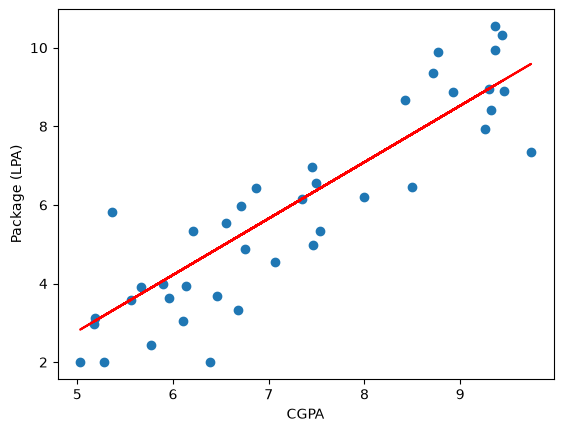

In [15]:
plt.scatter(X_test, y_test)
plt.plot(X_test, y_pred, color='red')
plt.xlabel('CGPA')
plt.ylabel('Package (LPA)')
plt.show()

In [16]:
import numpy as np

In [17]:
X_train = X_train.to_numpy().ravel()
y_train = y_train.to_numpy()

In [18]:
class MyLR:
    def _init_(self):
        self.m = None
        self.b = None
    def fit(self, X_train, y_train):
        numerator = 0
        denominator = 0
        for i in range(X_train.shape[0]):
            numerator += (
                (X_train[i] - X_train.mean())*
                (y_train[i] - y_train.mean())
            )
            denominator += (
            (X_train[i] - X_train.mean())**2
            )
        self.m = numerator/denominator
        self.b = y_train.mean() - self.m*X_train.mean()
    def predict(self, X_test):
        return self.m*X_test + self.b

In [19]:
model = MyLR()

In [20]:
model.fit(X_train, y_train)

In [21]:
y_pred = model.predict(X_test)

In [22]:
print(model.m)
print(model.b)

1.4357416767126832
-4.394124803013189


In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [24]:
mae = mean_absolute_error(y_test, y_pred)
print('Mean Absolute Error:', mae)
mse = mean_squared_error(y_test, y_pred)
print('Mean Squared Error:', mse)
rmse = np.sqrt(mse)
print('Root Mean Squared Error:', rmse)
r2 = r2_score(y_test, y_pred)
print('R2 Score:', r2)
n = X_test.shape[0]
p = X_test.shape[1]
adjusted_r2 = 1 - (1 - r2) * ((n - 1) / (n - p - 1))
print('Adjusted R2 Score:', adjusted_r2)

Mean Absolute Error: 0.919561661175415
Mean Squared Error: 1.298539731009996
Root Mean Squared Error: 1.139534874854647
R2 Score: 0.796627543599696
Adjusted R2 Score: 0.7912756368523196
